In [1]:
# Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
# =====================================================
# STEP 1: LOAD THE DATASET
# =====================================================

# 3A: Credit Card Fraud Dataset
data = pd.read_csv("creditcard.csv")

# Separate features and target
X = data.drop("Class", axis=1)
y = data["Class"]

In [3]:
# =====================================================
# STEP 2: PREPROCESS THE DATA
# =====================================================

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Select only normal transactions for training
# Class 0 = Normal, Class 1 = Fraud
X_train_normal = X_train[y_train == 0]

# Scale features using only normal training transactions
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
# =====================================================
# STEP 3: DEFINE THE AUTOENCODER MODEL
# =====================================================

input_dim = X_train.shape[1]

# Encoder
input_layer = keras.Input(shape=(input_dim,))

encoded = layers.Dense(32, activation='relu')(input_layer)
encoded = layers.Dense(16, activation='relu')(encoded)
encoded = layers.Dense(8, activation='relu')(encoded)

# Decoder
decoded = layers.Dense(16, activation='relu')(encoded)
decoded = layers.Dense(32, activation='relu')(decoded)
decoded = layers.Dense(input_dim, activation='linear')(decoded)

# Build Autoencoder
autoencoder = keras.Model(input_layer, decoded)


In [5]:
# =====================================================
# STEP 4: COMPILE THE MODEL
# =====================================================

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,334 (13.02 KB)

 Trainable params: 3,334 (13.02 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# =====================================================
# STEP 5: TRAIN THE AUTOENCODER
# =====================================================

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - loss: 0.6893 - mae: 0.5614 - val_loss: 0.5004 - val_mae: 0.5012
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4835 - mae: 0.4868 - val_loss: 0.4348 - val_mae: 0.4694
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.4273 - mae: 0.4593 - val_loss: 0.3897 - val_mae: 0.4440
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.3875 - mae: 0.4384 - val_loss: 0.3615 - val_mae: 0.4271
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.3599 - mae: 0.4212 - val_loss: 0.3531 - val_mae: 0.4206
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.3417 - mae: 0.4081 - val_loss: 0.3248 - val_mae: 0.3999
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.3252 - mae: 0.3966 - val_loss: 0.3110 - val_mae: 0.3896
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3125 - mae: 0.3869 - val_loss: 0.2992 - val_mae: 0.3813
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step -

In [7]:
# =====================================================
# STEP 6: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Reconstruct test data
X_pred = autoencoder.predict(X_test)

# Calculate Mean Squared Error
reconstruction_error = np.mean(
    np.square(X_test - X_pred), axis=1
)

# Set threshold using training reconstruction errors
train_pred = autoencoder.predict(X_train_normal)

train_error = np.mean(
    np.square(X_train_normal - train_pred), axis=1
)

# Threshold: 95th percentile of normal training errors
threshold = np.percentile(train_error, 95)

print("Reconstruction Error Threshold:", threshold)

# Detect anomalies
y_pred = (reconstruction_error > threshold).astype(int)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step
7108/7108 ━━━━━━━━━━━━━━━━━━━━ 29s 4ms/step
Reconstruction Error Threshold: 0.6871561286584047


In [8]:
# =====================================================
# STEP 7: EVALUATE MODEL PERFORMANCE
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))


Confusion Matrix:
[[53989  2875]
 [   11    87]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.89      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.92      0.52     56962
weighted avg       1.00      0.95      0.97     56962

Accuracy: 0.9493346441487307
Precision: 0.02937204591492235
Recall: 0.8877551020408163
F1 Score: 0.056862745098039215


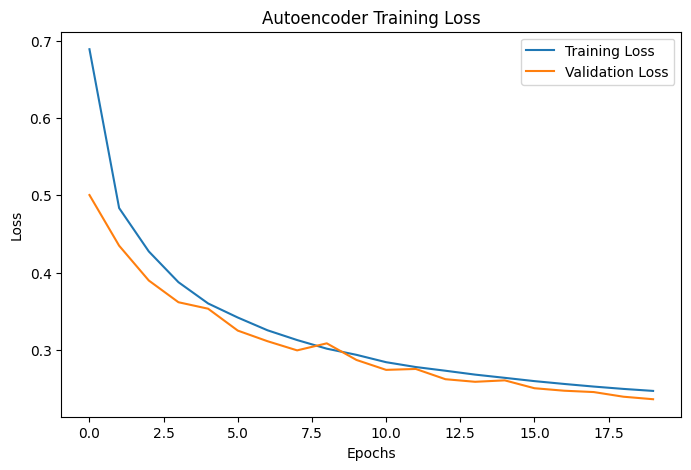

In [9]:
# =====================================================
# STEP 8: PLOT TRAINING LOSS
# =====================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

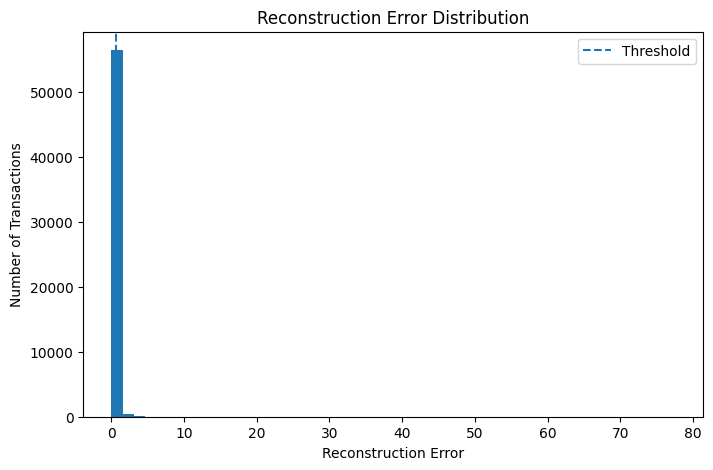

In [10]:
# =====================================================
# STEP 9: PLOT RECONSTRUCTION ERROR
# =====================================================

plt.figure(figsize=(8, 5))
plt.hist(reconstruction_error, bins=50)
plt.axvline(threshold, linestyle='--', label='Threshold')
plt.title('Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Transactions')
plt.legend()
plt.show()
